# Problem 2: A minimal Metropolis–Hastings sampler

A worked example from [Hogg & Foreman-Mackey, *Data analysis recipes: Using Markov Chain Monte Carlo*, Problem 2](https://arxiv.org/pdf/1710.06068v1).

We will sample a Gaussian with mean 2 and **variance** 2 using a Gaussian random walk. Only NumPy and Matplotlib are needed in the existing Python 3 kernel.

## Target, proposal, and acceptance

Our target density is
$$p(x)=\frac{1}{\sqrt{4\pi}}\exp\left[-\frac{(x-2)^2}{4}\right].$$
Here $\mathcal N(2,2)$ means mean 2 and variance 2, so the target standard deviation is $\sqrt2$.

Starting at the current state $x$, propose
$$x'=x+\epsilon,\qquad \epsilon\sim\mathcal N(0,1).$$
Thus the proposal $q(x'\mid x)$ has mean $x$ and variance 1 (standard deviation 1).

The general Metropolis–Hastings acceptance probability is
$$\alpha(x,x')=\min\left(1,\frac{p(x')q(x\mid x')}{p(x)q(x'\mid x)}\right).$$
The Gaussian random walk is symmetric: $q(x'\mid x)=q(x\mid x')$, since its density depends only on $(x'-x)^2$. The proposal terms cancel, leaving
$$\alpha(x,x')=\min\left(1,\frac{p(x')}{p(x)}\right).$$
Moves toward higher density are always accepted; moves toward lower density are sometimes accepted. If rejected, we keep the current state.

We only need the unnormalized log density
$$\ell(x)=-\frac{(x-2)^2}{4},$$
because the constant cancels in $\ell(x')-\ell(x)$. For $u\sim U(0,1)$, accept when
$$\log u<\min\left(0,\ell(x')-\ell(x)\right).$$
Using logarithms avoids underflow from evaluating tiny Gaussian densities.

## Run 50,000 transitions

Initialize at $x=0$ and fix the random seed at 42. Each stored entry is the state **after** a transition; the initial state is not a separate entry. A rejected proposal still contributes a stored state. We keep all 50,000 entries, including the initial transient; **no burn-in is discarded**.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def log_p(x):
    return -(x - 2) ** 2 / 4

rng = np.random.default_rng(42)
x = 0.0
samples = np.empty(50_000)
accepted = 0
for i in range(len(samples)):
    proposal = rng.normal(x, 1.0)
    if np.log(rng.random()) < min(0.0, log_p(proposal) - log_p(x)):
        x = proposal
        accepted += 1
    samples[i] = x

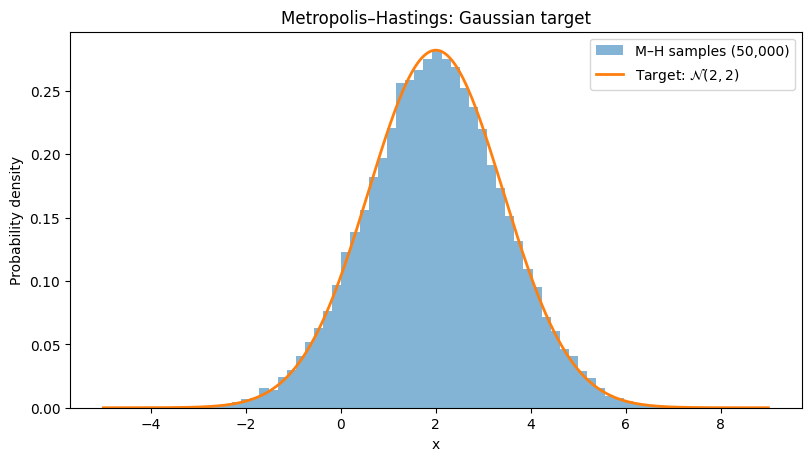

Sample mean: 1.9940 (target: 2)
Sample variance: 2.0765 (target: 2)
Acceptance fraction: 0.782


In [2]:
grid = np.linspace(-5, 9, 500)
density = np.exp(-(grid - 2) ** 2 / 4) / np.sqrt(4 * np.pi)
fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
ax.hist(samples, bins=60, density=True, alpha=0.55, label="M–H samples (50,000)")
ax.plot(grid, density, color="tab:orange", linewidth=2, label=r"Target: $\mathcal{N}(2,2)$")
ax.set(xlabel="x", ylabel="Probability density", title="Metropolis–Hastings: Gaussian target")
ax.legend()
plt.show()
print(f"Sample mean: {samples.mean():.4f} (target: 2)")
print(f"Sample variance: {samples.var():.4f} (target: 2)")
print(f"Acceptance fraction: {accepted / len(samples):.3f}")

## What can we conclude?

The density-normalized histogram approximates the true Gaussian density: its area is 1, so its height can be compared directly with the analytic curve. The sample mean and variance should be near 2, with finite-sample fluctuations.

The acceptance rule preserves the target distribution (through detailed balance). This Gaussian random walk can explore the whole real line, so over a sufficiently long run its time spent in each region reflects the target probability. Starting at 0 introduces an initial transient; we retain it here as specified. A matching histogram is a useful check, but does not by itself prove convergence.

**Repeated states are part of the algorithm.** When a proposal is rejected, the chain remains where it is for another step. Keeping only accepted moves would change the relative time spent in different regions and generally distort the sampled distribution.

Unlike the independent uniform draws in Problem 1, neighboring MCMC states are correlated. Consequently, 50,000 chain states generally provide less information than 50,000 independent draws from the target. The acceptance fraction describes how often proposals move the chain; it is not, by itself, a measure of sampling accuracy.